In [ ]:
!pip install -q statsmodels

import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from google.colab import drive

warnings.filterwarnings('ignore')       # statsmodels affiche beaucoup d'avertissements de convergence

drive.mount('/content/drive')
FINAL_PATH = '/content/drive/MyDrive/projet_conso/data/processed/dataset_hourly.parquet'
df = pd.read_parquet(FINAL_PATH)
print(f'Dataset : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')

Mounted at /content/drive
Dataset : 34,587 lignes × 15 colonnes


In [ ]:
TARGET  = 'global_active_power'
HORIZON = 24

SPLITS = {
    'train': ('2006-12-16', '2008-12-31 23:00'),
    'val':   ('2009-01-01', '2009-12-31 23:00'),
    'test':  ('2010-01-01', '2010-12-31 23:00'),
}
EXOG_COLS = ['is_weekend', 'is_holiday']      # calendrier connu à l'avance (variables exogènes)

y     = df[TARGET].to_numpy(float)             # en kW, pas besoin de normaliser pour SARIMA
X     = df[EXOG_COLS].to_numpy(float)
real  = df['is_imputed'].to_numpy() == 0
times = df.index


def daily_origins(split):
    """Positions des prévisions émises à minuit dont les 24 h sont entièrement dans la période."""
    start, end = SPLITS[split]
    t0 = np.arange(168, len(df) - HORIZON + 1)
    keep = ((times[t0] >= pd.Timestamp(start)) & (times[t0 + HORIZON - 1] <= pd.Timestamp(end))
            & (times[t0].hour == 0))
    return t0[keep]


def targets(origins):
    idx = origins[:, None] + np.arange(HORIZON)
    return y[idx], real[idx]


def compute_metrics(y_true, y_pred, mask):
    """Métriques en kW, uniquement sur les heures réellement mesurées."""
    t, p = y_true[mask], y_pred[mask]
    err = p - t
    return {
        'MAE (kW)':  np.mean(np.abs(err)),
        'RMSE (kW)': np.sqrt(np.mean(err ** 2)),
        'MAPE (%)':  np.mean(np.abs(err) / t) * 100,
        'WAPE (%)':  np.sum(np.abs(err)) / np.sum(t) * 100,
    }


for s in ['val', 'test']:
    o = daily_origins(s)
    print(f'{s:5s} : {len(o)} prévisions à minuit ({times[o[0]]:%Y-%m-%d} → {times[o[-1]]:%Y-%m-%d})')

val   : 365 prévisions à minuit (2009-01-01 → 2009-12-31)
test  : 329 prévisions à minuit (2010-01-01 → 2010-11-25)


In [ ]:
def fit_sarima(order, seasonal_order, n_weeks, use_exog, fit_end):
    """Ajuste SARIMA sur les n_weeks semaines qui précèdent fit_end (position exclue)."""
    a = fit_end - n_weeks * 168
    model = SARIMAX(y[a:fit_end], exog=X[a:fit_end] if use_exog else None,
                    order=order, seasonal_order=seasonal_order,
                    enforce_stationarity=False, enforce_invertibility=False)
    return model.fit(disp=False, maxiter=200)


def rolling_forecast(res, fit_end, origins, use_exog):
    """Prévisions de 24 h émises chaque jour à minuit, avec des paramètres FIXES.

    Le modèle « avance » dans le temps avec extend() : il intègre les vraies
    observations passées (autorisé) sans réestimer ses paramètres.
    """
    ex = (lambda a, b: X[a:b]) if use_exog else (lambda a, b: None)
    pos = fit_end
    preds = []
    for o in origins:
        if o > pos:                                        # intégrer les observations jusqu'à l'origine
            res = res.extend(y[pos:o], exog=ex(pos, o))
            pos = o
        preds.append(res.forecast(steps=HORIZON, exog=ex(o, o + HORIZON)))
    return np.array(preds)

In [ ]:
val_origins = daily_origins('val')
y_val, m_val = targets(val_origins)
fit_end_val = int(np.searchsorted(times, pd.Timestamp(SPLITS['val'][0])))   # = fin du train

CONFIGS = {
    'SARIMA(1,0,1)(1,1,1,24)':               dict(order=(1, 0, 1), seasonal_order=(1, 1, 1, 24), use_exog=False),
    'SARIMA(2,0,1)(1,1,1,24)':               dict(order=(2, 0, 1), seasonal_order=(1, 1, 1, 24), use_exog=False),
    'SARIMA(1,0,1)(0,1,1,24)':               dict(order=(1, 0, 1), seasonal_order=(0, 1, 1, 24), use_exog=False),
    'SARIMAX(1,0,1)(1,1,1,24) + calendrier': dict(order=(1, 0, 1), seasonal_order=(1, 1, 1, 24), use_exog=True),
}
N_WEEKS = 8      # 8 semaines d'historique pour estimer les paramètres (SARIMA est lent sur des séries longues)

tuning = pd.DataFrame()
for name, cfg in CONFIGS.items():
    t = time.time()
    res = fit_sarima(cfg['order'], cfg['seasonal_order'], N_WEEKS, cfg['use_exog'], fit_end_val)
    pred = rolling_forecast(res, fit_end_val, val_origins, cfg['use_exog'])
    m = compute_metrics(y_val, pred, m_val)
    tuning.loc[name, 'MAE val'] = m['MAE (kW)']
    tuning.loc[name, 'RMSE val'] = m['RMSE (kW)']
    tuning.loc[name, 'AIC'] = res.aic
    tuning.loc[name, 'Durée (s)'] = time.time() - t
    print(f'{name:40s} -> MAE val {m["MAE (kW)"]:.3f}  ({time.time() - t:.0f} s)')

tuning.sort_values('MAE val').round(3)

SARIMA(1,0,1)(1,1,1,24)                  -> MAE val 0.469  (15 s)
SARIMA(2,0,1)(1,1,1,24)                  -> MAE val 0.473  (16 s)
SARIMA(1,0,1)(0,1,1,24)                  -> MAE val 0.469  (7 s)
SARIMAX(1,0,1)(1,1,1,24) + calendrier    -> MAE val 0.474  (15 s)


,MAE val,RMSE val,AIC,Durée (s)
"SARIMA(1,0,1)(0,1,1,24)",0.469,0.659,2455.642,7.081
"SARIMA(1,0,1)(1,1,1,24)",0.469,0.660,2467.940,14.752
"SARIMA(2,0,1)(1,1,1,24)",0.473,0.662,2464.601,16.303
"SARIMAX(1,0,1)(1,1,1,24) + calendrier",0.474,0.656,2459.249,15.242


In [ ]:
FINAL_NAME = tuning['MAE val'].idxmin()          # meilleure configuration en validation
FINAL = CONFIGS[FINAL_NAME]
print('Configuration retenue :', FINAL_NAME)

# Paramètres estimés sur le TRAIN uniquement (comme les autres modèles) ;
# le modèle intègre ensuite les observations de 2009 (du passé) avant de prévoir 2010.
res_final = fit_sarima(FINAL['order'], FINAL['seasonal_order'], N_WEEKS, FINAL['use_exog'], fit_end_val)
test_origins = daily_origins('test')
y_test, m_test = targets(test_origins)
pred_sarima = rolling_forecast(res_final, fit_end_val, test_origins, FINAL['use_exog'])

# Baselines sur les MÊMES prévisions (à minuit)
idx = test_origins[:, None] + np.arange(HORIZON)
tr = df.loc[SPLITS['train'][0]:SPLITS['train'][1]]
tr = tr[tr['is_imputed'] == 0]
profile = tr.groupby(['day_of_week', 'hour'])[TARGET].mean()
ft = times[idx.ravel()]
pred_profile = profile.reindex(list(zip(ft.dayofweek, ft.hour))).to_numpy().reshape(-1, HORIZON)

preds = {
    'Persistance J-1':             y[idx - 24],
    'Persistance J-7':             y[idx - 168],
    'Profil moyen (jour × heure)': pred_profile,
    'SARIMA':                      pred_sarima,
}
results = pd.DataFrame({k: compute_metrics(y_test, p, m_test) for k, p in preds.items()}).T.round(3)
print('Prévision une fois par jour, à minuit (test 2010) :')
results

Configuration retenue : SARIMA(1,0,1)(0,1,1,24)
Prévision une fois par jour, à minuit (test 2010) :


,MAE (kW),RMSE (kW),MAPE (%),WAPE (%)
Persistance J-1,0.558,0.823,68.458,52.619
Persistance J-7,0.576,0.832,73.766,54.316
Profil moyen (jour × heure),0.513,0.687,77.827,48.332
SARIMA,0.454,0.625,64.068,42.818


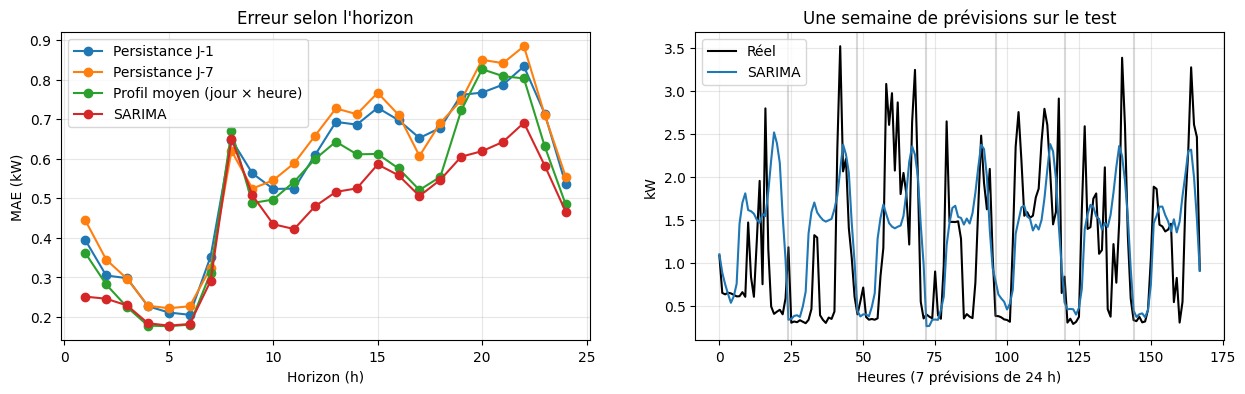

In [ ]:
def mae_by_horizon(y_true, y_pred, mask):
    return np.array([np.abs(y_true[mask[:, h], h] - y_pred[mask[:, h], h]).mean() for h in range(HORIZON)])

hours = np.arange(1, HORIZON + 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for name, p in preds.items():
    axes[0].plot(hours, mae_by_horizon(y_test, p, m_test), marker='o', label=name)
axes[0].set_xlabel('Horizon (h)'); axes[0].set_ylabel('MAE (kW)')
axes[0].set_title("Erreur selon l'horizon"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(y_test[:7].ravel(), 'k', label='Réel')
axes[1].plot(pred_sarima[:7].ravel(), label='SARIMA')
for d_ in range(1, 7):
    axes[1].axvline(24 * d_, color='grey', alpha=0.3)
axes[1].set_xlabel('Heures (7 prévisions de 24 h)'); axes[1].set_ylabel('kW')
axes[1].set_title('Une semaine de prévisions sur le test'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.show()